In [15]:
import seaborn as sns
from sklearn.datasets import make_blobs, load_iris # use to generate datasets for clustering 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [7]:
df = load_iris()
df

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [8]:
X = df.data
y = df.target

## Elbow Method (to find proper K)

In [19]:
wcss_values_for_each_k = []
for k in range(1,21):
    model = KMeans(
        n_clusters = k
    )
    model.fit_predict(X)
    inertia_or_wcss = model.inertia_
    wcss_values_for_each_k.append(inertia_or_wcss)

<Axes: >

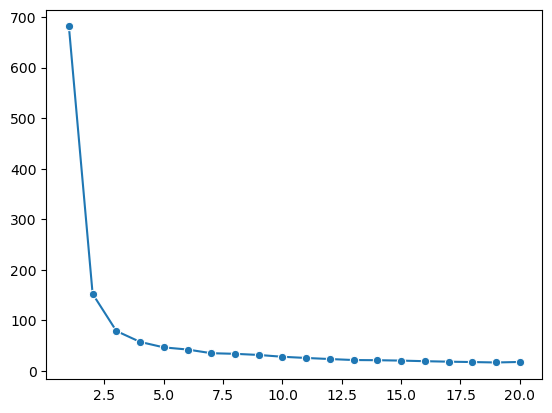

In [20]:
# create the plot 
sns.lineplot(x=range(1,21),y=wcss_values_for_each_k,marker='o')

### Using kneed KneeLocator

In [21]:
from kneed import KneeLocator

knee_value = KneeLocator(range(1,21),wcss_values_for_each_k,curve='convex',direction='decreasing')

In [22]:
print("Best K = ",knee_value.elbow)

Best K =  3


### Using Silhouette Score

In [26]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,21):
    model = KMeans(
        n_clusters = k
    )
    predicted_values = model.fit_predict(X)
    score = silhouette_score(X,predicted_values)
    scores.append(score)

<Axes: >

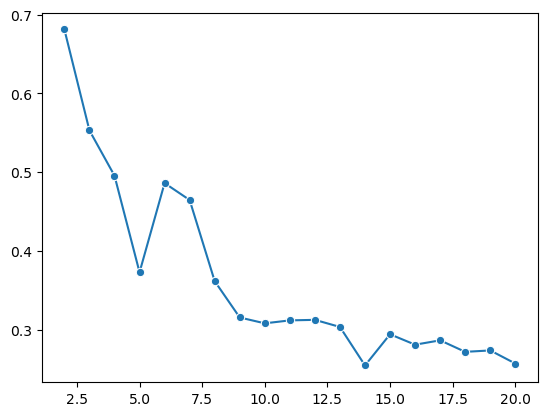

In [27]:
sns.lineplot(x=range(2,21),y=scores,marker="o")

In [46]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = KMeans(
        n_clusters = 3
    )
labels = model.fit_predict(X_scaled)


<Axes: >

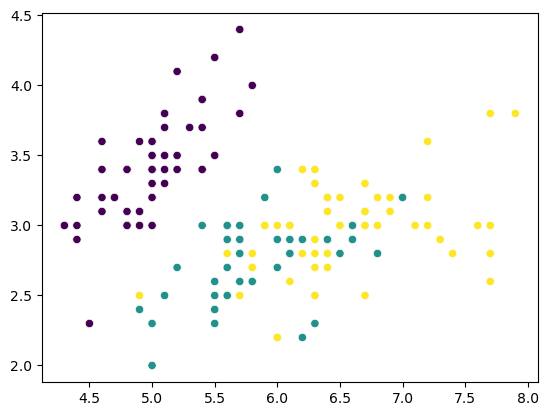

In [40]:
sns.scatterplot(x=X[:,0],y=X[:,1],c=y)

<Axes: >

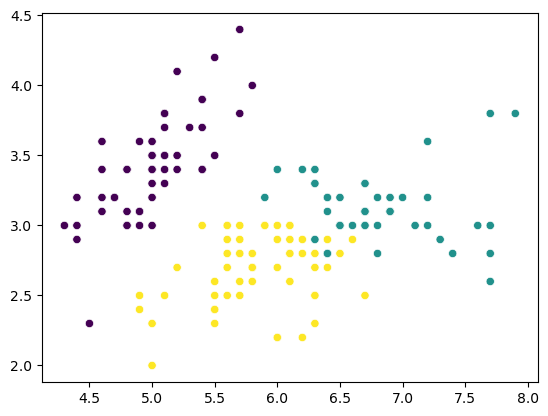

In [47]:
sns.scatterplot(x=X[:,0],y=X[:,1],c=labels)

<Axes: >

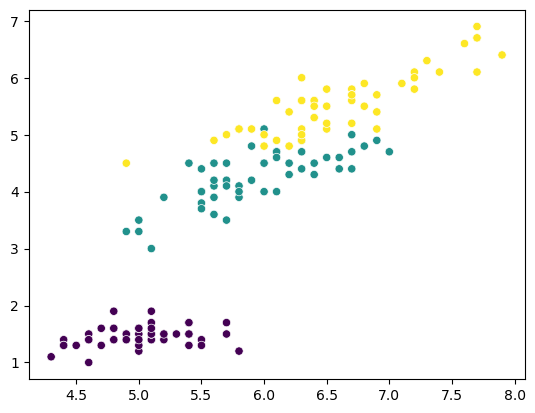

In [42]:
sns.scatterplot(x=X[:,0],y=X[:,2],c=y)

<Axes: >

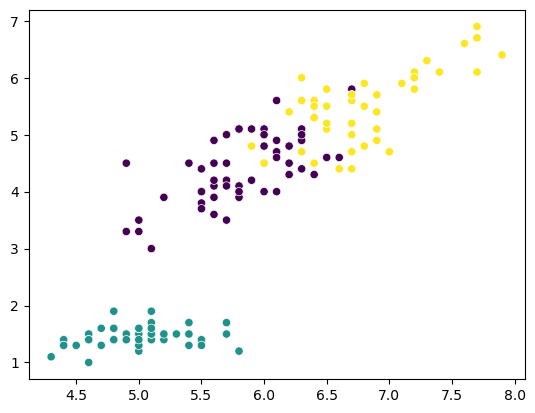

In [43]:
sns.scatterplot(x=X[:,0],y=X[:,2],c=labels)

In [48]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 2)

pca_data = pca.fit_transform(X_scaled)

In [55]:
model = KMeans(
        n_clusters = 3
    )
labels = model.fit_predict(pca_data)

<Axes: >

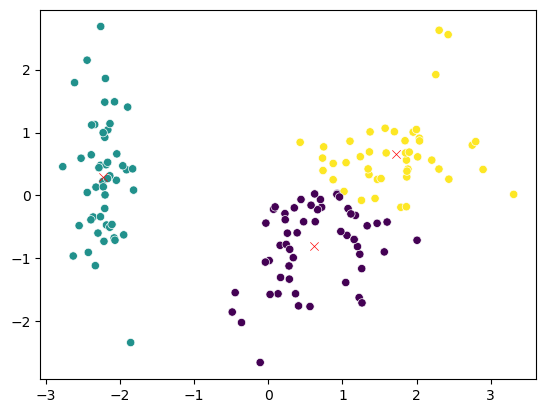

In [64]:
sns.scatterplot(x=pca_data[:,0],y=pca_data[:,1],c=labels)
sns.scatterplot(x=model.cluster_centers_[:,0],y=model.cluster_centers_[:,1],marker="x",c='red')

array([[-2.26470281,  0.4800266 ],
       [-2.08096115, -0.67413356],
       [-2.36422905, -0.34190802],
       [-2.29938422, -0.59739451],
       [-2.38984217,  0.64683538],
       [-2.07563095,  1.48917752],
       [-2.44402884,  0.0476442 ],
       [-2.23284716,  0.22314807],
       [-2.33464048, -1.11532768],
       [-2.18432817, -0.46901356],
       [-2.1663101 ,  1.04369065],
       [-2.32613087,  0.13307834],
       [-2.2184509 , -0.72867617],
       [-2.6331007 , -0.96150673],
       [-2.1987406 ,  1.86005711],
       [-2.26221453,  2.68628449],
       [-2.2075877 ,  1.48360936],
       [-2.19034951,  0.48883832],
       [-1.898572  ,  1.40501879],
       [-2.34336905,  1.12784938],
       [-1.914323  ,  0.40885571],
       [-2.20701284,  0.92412143],
       [-2.7743447 ,  0.45834367],
       [-1.81866953,  0.08555853],
       [-2.22716331,  0.13725446],
       [-1.95184633, -0.62561859],
       [-2.05115137,  0.24216355],
       [-2.16857717,  0.52714953],
       [-2.13956345,